# bai 1

In [30]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

base_test = np.full_like(y_test, y_train.mean(), dtype=float)
base_train = np.full_like(y_train, y_train.mean(), dtype=float)
baseline_mse = mean_squared_error(y_test, base_test)
baseline_r2 = r2_score(y_test, base_test)

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
model_mse = mean_squared_error(y_test, pred)
model_r2 = r2_score(y_test, pred)

improvement = (baseline_mse - model_mse) / baseline_mse * 100
print(f"baseline_mse:{baseline_mse}")
print(f"baseline_r2:{baseline_r2}")
print(f"model_mse:{model_mse}")
print(f"model_r2:{model_r2}")
print(f"improvement:{improvement}")

assert np.isclose(r2_score(y_train, base_train), 0)
assert -0.05 < baseline_r2 < 0
assert 1 - model_r2 > 0.5

baseline_mse:5361.533457238513
baseline_r2:-0.011962984778542296
model_mse:2900.193628493482
model_r2:0.4526027629719195
improvement:45.90738542201987


# bai 2

In [31]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


rows = []
for d in [1, 2, 3, 4]:
    pipe = Pipeline([("poly", PolynomialFeatures(degree=d)),
                     ("lr", LinearRegression())])
    pipe.fit(X_train, y_train)
    train_r2 = r2_score(y_train, pipe.predict(X_train))
    test_r2 = r2_score(y_test, pipe.predict(X_test))
    rows.append({
        "degree": d,
        "n_features": pipe.named_steps["poly"].n_output_features_,
        "train_r2": train_r2,
        "test_r2": test_r2,
        "gap": train_r2 - test_r2,
    })

df = pd.DataFrame(rows)
print(df.round(4))


first_diverge = int(df.loc[df["gap"] > 0.1, "degree"].iloc[0])
best_degree = int(df.loc[df["test_r2"].idxmax(), "degree"])

assert first_diverge == 2
assert best_degree == 1
assert df.loc[df["degree"] == 4, "n_features"].iloc[0] > len(X_train)

   degree  n_features  train_r2  test_r2      gap
0       1          11    0.5279   0.4526   0.0753
1       2          66    0.6062   0.4156   0.1905
2       3         286    0.8566  -5.2120   6.0686
3       4        1001    1.0000 -26.7281  27.7281


# bai 3

In [32]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import r2_score


scaler = StandardScaler().fit(X_train)
Xtr = scaler.transform(X_train)
Xte = scaler.transform(X_test)

alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000]

def run(model_cls, with_zeros=False):
    rows = []
    for a in alphas:
        m = model_cls(alpha=a).fit(Xtr, y_train)
        row = {
            "alpha": a,
            "train_r2": r2_score(y_train, m.predict(Xtr)),
            "test_r2": r2_score(y_test, m.predict(Xte)),
            "sum_abs_coef": np.abs(m.coef_).sum(),
        }
        if with_zeros:
            row["n_zero"] = int((m.coef_ == 0).sum())
        rows.append(row)
    return pd.DataFrame(rows)

ridge_df = run(Ridge)
lasso_df = run(Lasso, with_zeros=True)   


print("Ridge"); print(ridge_df.round(4))
print("Lasso"); print(lasso_df.round(4))

def kiem_tra(ten, df):
    train = df["train_r2"].values
    test = df["test_r2"].values

    ok1 = all(train[i + 1] <= train[i] + 1e-12 for i in range(len(train) - 1))

    best_idx = int(np.argmax(test))
    ok2 = 0 < best_idx < len(test) - 1

    ok3 = test.max() - test[-1] > 0.1

    ok4 = train[-1] < 0.1

    for i, ok in enumerate([ok1, ok2, ok3, ok4], start=1):
        print(f"{ten} - kiểm tra {i}: {'OK' if ok else 'SAI'}")
    print(f"{ten}: alpha tốt nhất = {df['alpha'].iloc[best_idx]}, test R² = {test[best_idx]:.4f}")

kiem_tra("Ridge", ridge_df)
kiem_tra("Lasso", lasso_df)


base_r2 = r2_score(y_test, np.full_like(y_test, y_train.mean(), dtype=float))
if np.isclose(lasso_df["test_r2"].iloc[-1], base_r2):
    print(f"OK: Lasso alpha lớn nhất có R² = {base_r2:.4f}, bằng baseline")
else:
    print("SAI: R² của Lasso ở alpha lớn nhất khác baseline")

Ridge
      alpha  train_r2  test_r2  sum_abs_coef
0      0.01    0.5279   0.4526      182.7722
1      0.10    0.5279   0.4528      179.7379
2      1.00    0.5276   0.4541      156.4183
3     10.00    0.5248   0.4572      108.7037
4    100.00    0.5118   0.4605       89.6454
5   1000.00    0.3564   0.3485       41.3465
6  10000.00    0.0864   0.0808        8.1558
Lasso
      alpha  train_r2  test_r2  sum_abs_coef  n_zero
0      0.01    0.5279   0.4529      178.8990       0
1      0.10    0.5272   0.4555      140.9604       0
2      1.00    0.5225   0.4669       97.2693       1
3     10.00    0.4651   0.4463       53.6206       6
4    100.00    0.0000  -0.0120        0.0000      10
5   1000.00    0.0000  -0.0120        0.0000      10
6  10000.00    0.0000  -0.0120        0.0000      10
Ridge - kiểm tra 1: OK
Ridge - kiểm tra 2: OK
Ridge - kiểm tra 3: OK
Ridge - kiểm tra 4: OK
Ridge: alpha tốt nhất = 100.0, test R² = 0.4605
Lasso - kiểm tra 1: OK
Lasso - kiểm tra 2: OK
Lasso - kiểm tra 3

# bai4

In [33]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression

X, y = load_diabetes(return_X_y=True)


kf = KFold(n_splits=5, shuffle=True, random_state=42)


manual_scores = []
for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
    model = LinearRegression()                      
    model.fit(X[train_idx], y[train_idx])
    score = model.score(X[val_idx], y[val_idx])     
    manual_scores.append(score)
    print(f"Fold {fold}: R² = {score:.4f}")

manual_scores = np.array(manual_scores)


print(f"Mean = {np.mean(manual_scores):.4f}, Std = {np.std(manual_scores):.4f}")

print(manual_scores)
sk_scores = cross_val_score(LinearRegression(), X, y, cv=kf)
if np.allclose(manual_scores, sk_scores):
    print(sk_scores)
    print("OK: điểm tự tính khớp với cross_val_score")
else:
    print("SAI: điểm tự tính khác cross_val_score")
    print("Tự tính :", manual_scores.round(4))
    print("sklearn :", sk_scores.round(4))

Fold 1: R² = 0.4526
Fold 2: R² = 0.5732
Fold 3: R² = 0.3914
Fold 4: R² = 0.5843
Fold 5: R² = 0.3908
Mean = 0.4785, Std = 0.0850
[0.45260276 0.57320015 0.39144785 0.58428888 0.39081186]
[0.45260276 0.57320015 0.39144785 0.58428888 0.39081186]
OK: điểm tự tính khớp với cross_val_score


# bai 5

In [34]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge


data = load_diabetes()
X, y = data.data, data.target
feature_names = list(data.feature_names)  

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train) 
X_test_s = scaler.transform(X_test)        


corr = np.array([np.corrcoef(X_train_s[:, j], y_train)[0, 1]
                 for j in range(X_train_s.shape[1])])
print (corr)

ridge = Ridge(alpha=1.0).fit(X_train_s, y_train)
coef = ridge.coef_


df = pd.DataFrame({"feature": feature_names, "corr": corr, "coef": coef})
df["rank_corr"] = df["corr"].abs().rank(ascending=False).astype(int)
df["rank_coef"] = df["coef"].abs().rank(ascending=False).astype(int)
df["rank_gap"] = (df["rank_corr"] - df["rank_coef"]).abs()

rho, _ = spearmanr(df["corr"].abs(), df["coef"].abs())
print(df.round(3))
print("Spearman:", round(rho, 4))


assert rho < 0.6

worst = df.loc[df["rank_gap"].idxmax(), "feature"]
j = feature_names.index(worst)
C = np.corrcoef(X_train_s, rowvar=False)
np.fill_diagonal(C, 0)
partner_idx = np.abs(C[j]).argmax()
print(f"{worst}: partner = {feature_names[partner_idx]}, r = {C[j, partner_idx]:.3f}")
assert np.abs(C[j]).max() > 0.7

flipped = df[np.sign(df["corr"]) != np.sign(df["coef"])]["feature"].tolist()
print("Sign flips:", flipped)
assert len(flipped) >= 1

[ 0.19650968  0.00711617  0.60475129  0.44477039  0.1995472   0.15492181
 -0.38399951  0.42509412  0.55218311  0.39036312]
  feature   corr    coef  rank_corr  rank_coef  rank_gap
0     age  0.197   1.807          8         10         2
1     sex  0.007 -11.448         10          7         3
2     bmi  0.605  25.733          1          3         2
3      bp  0.445  16.734          3          5         2
4      s1  0.200 -34.672          7          1         6
5      s2  0.155  17.053          9          4         5
6      s3 -0.384   3.370          6          8         2
7      s4  0.425  11.764          4          6         2
8      s5  0.552  31.378          2          2         0
9      s6  0.390   2.458          5          9         4
Spearman: 0.3576
s1: partner = s2, r = 0.891
Sign flips: ['sex', 's1', 's3']


bai 6

In [35]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)


data = load_breast_cancer()
y = (data.target == 0).astype(int)
X = data.data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(len(y_test), y_test.sum())   

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
logreg = LogisticRegression(max_iter=5000).fit(X_train, y_train)


def evaluate(model):
    pred = model.predict(X_test)
    return {
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "cm": confusion_matrix(y_test, pred),
    }

m_dummy = evaluate(dummy)
m_lr = evaluate(logreg)

for name, m in [("Dummy", m_dummy), ("LogReg", m_lr)]:
    print(name, {k: (round(v, 4) if k != "cm" else v.tolist()) for k, v in m.items()})


assert np.isclose(m_dummy["accuracy"], 1 - y_test.mean())
assert m_dummy["recall"] == 0.0

accuracy_gap = m_lr["accuracy"] - m_dummy["accuracy"]
recall_gap = m_lr["recall"] - m_dummy["recall"]
print(f"accuracy_gap = {accuracy_gap:.4f}, recall_gap = {recall_gap:.4f}")
assert recall_gap > accuracy_gap

114 42


Dummy {'accuracy': 0.6316, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'cm': [[72, 0], [42, 0]]}
LogReg {'accuracy': 0.9386, 'precision': 0.973, 'recall': 0.8571, 'f1': 0.9114, 'cm': [[71, 1], [6, 36]]}
accuracy_gap = 0.3070, recall_gap = 0.8571


# bai 7

In [36]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score


proba = logreg.predict_proba(X_test)[:, 1]


thr = np.round(np.arange(0.90, 0.0, -0.01), 2)
assert len(thr) == 90

rows = []
for t in thr:
    pred = (proba >= t).astype(int)
    rows.append({
        "threshold": t,
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
    })


sweep = pd.DataFrame(rows)
print(sweep[sweep["threshold"].isin([0.90, 0.50, 0.30, 0.21, 0.20, 0.10, 0.01])].round(4))


ok = sweep[sweep["recall"] >= 0.97]
best = ok.loc[ok["threshold"].idxmax()]
print("Best threshold:", best["threshold"],
      "| recall:", round(best["recall"], 4),
      "| precision:", round(best["precision"], 4))


default = sweep[sweep["threshold"] == 0.50].iloc[0]
lost = default["precision"] - best["precision"]
extra = int(round((best["recall"] - default["recall"]) * y_test.sum()))
print(f"Precision given up: {lost:.4f}, extra malignant caught: {extra}")


r_021 = sweep.loc[sweep["threshold"] == 0.21, "recall"].iloc[0]
assert r_021 < 0.97
assert best["threshold"] == 0.20

    threshold  precision  recall
0        0.90     1.0000  0.7143
40       0.50     0.9730  0.8571
60       0.30     0.9268  0.9048
69       0.21     0.9091  0.9524
70       0.20     0.9111  0.9762
80       0.10     0.8750  1.0000
89       0.01     0.7000  1.0000
Best threshold: 0.2 | recall: 0.9762 | precision: 0.9111
Precision given up: 0.0619, extra malignant caught: 5


# bai 8

In [37]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_val_score

param_grid = {"C": [0.01, 0.1, 1, 10, 100], "penalty": ["l1", "l2"]}
grid = GridSearchCV(
    LogisticRegression(solver="liblinear", max_iter=5000),
    param_grid,
    scoring="f1",
    cv=5,
)

grid.fit(X_train, y_train)
print("best_params_:", grid.best_params_)
print("best_score_ :", round(grid.best_score_, 4))


default_scores = cross_val_score(
    LogisticRegression(max_iter=5000),
    X_train, y_train, scoring="f1", cv=5,
)
default_mean = default_scores.mean()
default_fold_std = default_scores.std()
print("default mean:", round(default_mean, 4), "| std:", round(default_fold_std, 4))


gain = grid.best_score_ - default_mean
tuning_worth_it = gain > default_fold_std
print(f"gain = {gain:.4f}, std = {default_fold_std:.4f}, worth it: {tuning_worth_it}")

assert not tuning_worth_it

/home/hoan.nguyen@rikai.technology/hoan_intern_rikai/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/hoan.nguyen@rikai.technology/hoan_intern_rikai/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/hoan.nguyen@rikai.technology/hoan_intern_rikai/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this w

best_params_: {'C': 10, 'penalty': 'l1'}
best_score_ : 0.9553
default mean: 0.9364 | std: 0.0335
gain = 0.0189, std = 0.0335, worth it: False


# bai 9

                    accuracy  precision  recall      f1  roc_auc
model                                                           
LogisticRegression    0.9649     0.9750  0.9286  0.9512   0.9960
KNN                   0.9561     0.9744  0.9048  0.9383   0.9823
DecisionTree          0.9298     0.9048  0.9048  0.9048   0.9246
LogisticRegression [[71, 1], [3, 39]]
KNN [[71, 1], [4, 38]]
DecisionTree [[68, 4], [4, 38]]


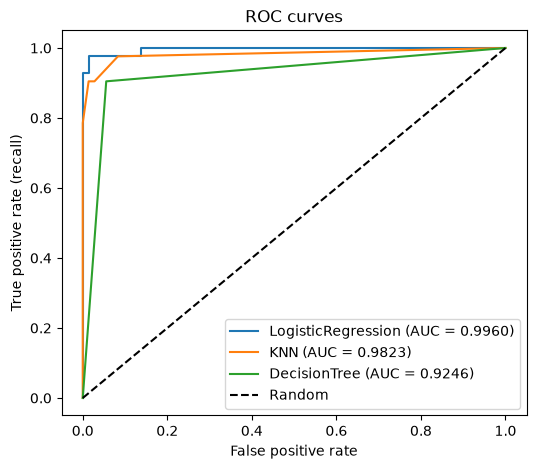

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix)


data = load_breast_cancer()
y = (data.target == 0).astype(int)
X = data.data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)


scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)


models = {
    "LogisticRegression": (LogisticRegression(max_iter=5000), X_train_s, X_test_s),
    "KNN": (KNeighborsClassifier(), X_train_s, X_test_s),
    "DecisionTree": (DecisionTreeClassifier(random_state=42), X_train, X_test),
}


rows, cms, probas = [], {}, {}
for name, (model, Xtr, Xte) in models.items():
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    probas[name] = proba
    cms[name] = confusion_matrix(y_test, pred)
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
    })

table = pd.DataFrame(rows).set_index("model")
print(table.round(4))
for name, cm in cms.items():
    print(name, cm.tolist())


plt.figure(figsize=(6, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {table.loc[name, 'roc_auc']:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves")
plt.legend(loc="lower right")
plt.show()


def pick_for_screening(table, min_precision=0.90):
    ok = table[table["precision"] >= min_precision]
    return ok["recall"].idxmax()

assert pick_for_screening(table) == "LogisticRegression"

order = table.sort_values("roc_auc", ascending=False).index.tolist()
assert order == ["LogisticRegression", "KNN", "DecisionTree"]

# bai 10

In [39]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score


iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
pred = model.predict(X_test)


print(classification_report(y_test, pred, target_names=iris.target_names))

rep = classification_report(y_test, pred, output_dict=True)
classes = ["0", "1", "2"]                      # khóa của từng lớp trong dict
f1 = np.array([rep[c]["f1-score"] for c in classes])
support = np.array([rep[c]["support"] for c in classes])

macro_f1 = f1.mean()
weighted_f1 = (f1 * support).sum() / support.sum()
print("per-class F1:", f1.round(4), "| support:", support)
print("macro:", round(macro_f1, 4), "| weighted:", round(weighted_f1, 4))

assert np.isclose(macro_f1, rep["macro avg"]["f1-score"])
assert np.isclose(weighted_f1, rep["weighted avg"]["f1-score"])


assert np.isclose(macro_f1, weighted_f1)


y_true = [0] * 90 + [1] * 5 + [2] * 5
y_pred = [0] * 100

macro_imb = f1_score(y_true, y_pred, average="macro", zero_division=0)
weighted_imb = f1_score(y_true, y_pred, average="weighted", zero_division=0)
print(f"macro = {macro_imb:.4f}, weighted = {weighted_imb:.4f}, "
      f"gap = {weighted_imb - macro_imb:.4f}")

assert weighted_imb - macro_imb > 0.5

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

per-class F1: [1.     0.9474 0.9524] | support: [10. 10. 10.]
macro: 0.9666 | weighted: 0.9666
macro = 0.3158, weighted = 0.8526, gap = 0.5368


# bai 11

In [40]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif

iris = load_iris()
X, y = iris.data, iris.target


pipe = Pipeline([("scaler", StandardScaler()), ("svc", SVC())])


param_grid = {"svc__C": [0.1, 1, 10, 100], "svc__kernel": ["linear", "rbf"]}
grid_pipe = GridSearchCV(pipe, param_grid, cv=5)
grid_pipe.fit(X, y)
print("best:", grid_pipe.best_params_, "| CV acc:", round(grid_pipe.best_score_, 4))


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(skf.split(X, y))

mean_all = StandardScaler().fit(X).mean_
mean_train = StandardScaler().fit(X[train_idx]).mean_
print("max abs diff:", np.abs(mean_all - mean_train).max().round(4))
assert not np.allclose(mean_all, mean_train)


X_leaky = StandardScaler().fit_transform(X)
grid_leaky = GridSearchCV(
    SVC(),
    {"C": [0.1, 1, 10, 100], "kernel": ["linear", "rbf"]},
    cv=5,
)
grid_leaky.fit(X_leaky, y)
print("pipeline:", round(grid_pipe.best_score_, 4),
      "| leaky:", round(grid_leaky.best_score_, 4),
      "| diff:", round(abs(grid_pipe.best_score_ - grid_leaky.best_score_), 4))


rng = np.random.RandomState(42)
X_noise = rng.randn(100, 2000)
y_noise = rng.randint(0, 2, 100)


X_sel = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
score_leaky = cross_val_score(LogisticRegression(max_iter=1000), X_sel, y_noise, cv=5).mean()


pipe_noise = Pipeline([
    ("select", SelectKBest(f_classif, k=20)),
    ("clf", LogisticRegression(max_iter=1000)),
])
score_clean = cross_val_score(pipe_noise, X_noise, y_noise, cv=5).mean()

print(f"select-first: {score_leaky:.4f} | pipeline: {score_clean:.4f}")
assert score_leaky > 0.75
assert score_clean < 0.65

best: {'svc__C': 10, 'svc__kernel': 'rbf'} | CV acc: 0.9733
max abs diff: 0.0292
pipeline: 0.9733 | leaky: 0.9733 | diff: 0.0
select-first: 0.8600 | pipeline: 0.5300


# bai 12

k=1: train 1.0000, test 0.9298
k=101: train 0.9297, test 0.9211
best_k = 7 (train 0.9709, validation 0.9692)


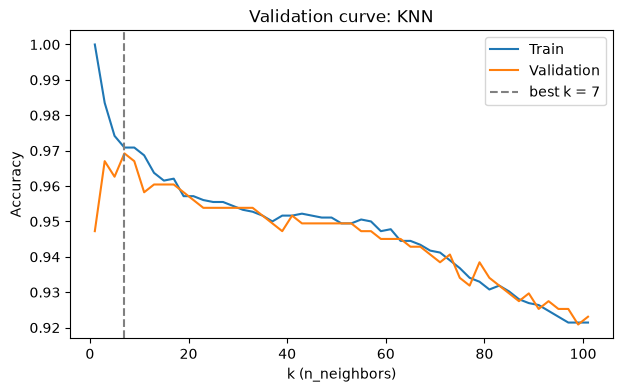

k=1: train 1.0000, val 0.9473, gap +0.0527 -> overfit
k=101: train 0.9214, val 0.9231, gap -0.0016 -> underfit
k=7: train 0.9709, val 0.9692, gap +0.0016 -> good fit


In [41]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier


data = load_breast_cancer()
y = (data.target == 0).astype(int)
X = data.data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

def knn(k):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])


for k in (1, 101):
    m = knn(k).fit(X_train, y_train)
    print(f"k={k}: train {m.score(X_train, y_train):.4f}, "
          f"test {m.score(X_test, y_test):.4f}")


param_range = list(range(1, 102, 2))   # 51 giá trị
train_scores, val_scores = validation_curve(
    knn(1), X_train, y_train,
    param_name="knn__n_neighbors", param_range=param_range, cv=5,
)
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

best_idx = val_mean.argmax()
best_k = param_range[best_idx]
print(f"best_k = {best_k} (train {train_mean[best_idx]:.4f}, "
      f"validation {val_mean[best_idx]:.4f})")

plt.figure(figsize=(7, 4))
plt.plot(param_range, train_mean, label="Train")
plt.plot(param_range, val_mean, label="Validation")
plt.axvline(best_k, color="gray", linestyle="--", label=f"best k = {best_k}")
plt.xlabel("k (n_neighbors)")
plt.ylabel("Accuracy")
plt.title("Validation curve: KNN")
plt.legend()
plt.show()


def diagnose(train, val):
    if train - val > 0.04:
        return "overfit"
    if val < 0.93:
        return "underfit"
    return "good fit"

labels = []
for k in (1, 101, best_k):
    i = param_range.index(k)
    t, v = train_mean[i], val_mean[i]
    labels.append(diagnose(t, v))
    print(f"k={k}: train {t:.4f}, val {v:.4f}, gap {t - v:+.4f} -> {labels[-1]}")

assert labels == ["overfit", "underfit", "good fit"]

# bai 13

In [42]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score


def total_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return 10 * fn + 1 * fp


for name, (model, Xtr, Xte) in models.items():
    pred = model.predict(Xte)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{name}: FN={fn}, FP={fp}, cost={total_cost(y_test, pred)}")



proba_lr = probas["LogisticRegression"]
thr = np.round(np.arange(0.90, 0.0, -0.01), 2)

rows = []
for t in thr:
    pred = (proba_lr >= t).astype(int)
    rows.append({
        "threshold": t,
        "cost": total_cost(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
    })
sweep = pd.DataFrame(rows)

min_cost = sweep["cost"].min()
best = sweep[sweep["cost"] == min_cost]
print("Thresholds reaching min cost:", best["threshold"].tolist())
best_t = best["threshold"].iloc[0]
b = sweep[sweep["threshold"] == best_t].iloc[0]
print(f"best_t={best_t}, cost={int(b['cost'])}, "
      f"precision={b['precision']:.4f}, recall={b['recall']:.4f}")


default_cost = int(sweep.loc[sweep["threshold"] == 0.50, "cost"].iloc[0])
saved = default_cost - min_cost
print(f"saved {saved} ({saved / default_cost:.1%})")


f1_t = sweep.loc[sweep["f1"].idxmax(), "threshold"]
f1_cost = int(sweep.loc[sweep["threshold"] == f1_t, "cost"].iloc[0])
print(f"max-F1 threshold = {f1_t}, cost = {f1_cost}")

assert best_t == 0.06
assert min_cost == 10
assert default_cost == 31

LogisticRegression: FN=3, FP=1, cost=31
KNN: FN=4, FP=1, cost=41
DecisionTree: FN=4, FP=4, cost=44
Thresholds reaching min cost: [0.06]
best_t=0.06, cost=10, precision=0.8077, recall=1.0000
saved 21 (67.7%)
max-F1 threshold = 0.31, cost = 11


# bai 14

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import r2_score, confusion_matrix, precision_score, recall_score

Xd, yd = load_diabetes(return_X_y=True)
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.2, random_state=42)


rows = []
for d in [1, 2, 3, 4]:
    pipe = Pipeline([("poly", PolynomialFeatures(degree=d)),
                     ("lr", LinearRegression())])
    pipe.fit(Xd_train, yd_train)
    train_r2 = r2_score(yd_train, pipe.predict(Xd_train))
    test_r2 = r2_score(yd_test, pipe.predict(Xd_test))
    rows.append({"degree": d,
                 "n_features": pipe.named_steps["poly"].n_output_features_,
                 "train_r2": train_r2, "test_r2": test_r2,
                 "gap": train_r2 - test_r2})
poly_df = pd.DataFrame(rows)


scaler_d = StandardScaler().fit(Xd_train)
Xtr = scaler_d.transform(Xd_train)
Xte = scaler_d.transform(Xd_test)
alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000]

def run(model_cls, with_zeros=False):
    rows = []
    for a in alphas:
        m = model_cls(alpha=a).fit(Xtr, yd_train)
        row = {"alpha": a,
               "train_r2": r2_score(yd_train, m.predict(Xtr)),
               "test_r2": r2_score(yd_test, m.predict(Xte)),
               "sum_abs_coef": np.abs(m.coef_).sum()}
        if with_zeros:
            row["n_zero"] = int((m.coef_ == 0).sum())
        rows.append(row)
    return pd.DataFrame(rows)

ridge_df = run(Ridge)
lasso_df = run(Lasso, with_zeros=True)


cancer = load_breast_cancer()
yc = (cancer.target == 0).astype(int)
Xc = cancer.data
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, stratify=yc, random_state=42)
scaler_c = StandardScaler().fit(Xc_train)
Xc_train_s = scaler_c.transform(Xc_train)
Xc_test_s = scaler_c.transform(Xc_test)


models = {
    "LogisticRegression": (LogisticRegression(max_iter=5000), Xc_train_s, Xc_test_s),
    "KNN": (KNeighborsClassifier(), Xc_train_s, Xc_test_s),
    "DecisionTree": (DecisionTreeClassifier(random_state=42), Xc_train, Xc_test),
}
rows, probas = [], {}
for name, (model, Xtr_c, Xte_c) in models.items():
    model.fit(Xtr_c, yc_train)
    pred = model.predict(Xte_c)
    probas[name] = model.predict_proba(Xte_c)[:, 1]
    rows.append({"model": name,
                 "precision": precision_score(yc_test, pred, zero_division=0),
                 "recall": recall_score(yc_test, pred)})
table = pd.DataFrame(rows).set_index("model")

def pick_for_screening(table, min_precision=0.90):
    ok = table[table["precision"] >= min_precision]
    return ok["recall"].idxmax()


def total_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return 10 * fn + 1 * fp

thr = np.round(np.arange(0.90, 0.0, -0.01), 2)
cost_sweep = pd.DataFrame([
    {"threshold": t,
     "cost": total_cost(yc_test, (probas["LogisticRegression"] >= t).astype(int))}
    for t in thr])

min_cost = int(cost_sweep["cost"].min())
best_t = float(cost_sweep.loc[cost_sweep["cost"] == min_cost, "threshold"].iloc[0])
default_cost = int(cost_sweep.loc[cost_sweep["threshold"] == 0.50, "cost"].iloc[0])


best_poly = poly_df.loc[poly_df["test_r2"].idxmax()]
best_ridge = ridge_df.loc[ridge_df["test_r2"].idxmax()]
best_lasso = lasso_df.loc[lasso_df["test_r2"].idxmax()]

clf_name = pick_for_screening(table)
clf_recall = recall_score(yc_test, (probas[clf_name] >= best_t).astype(int))

summary = pd.DataFrame([
    {"decision": "polynomial degree", "choice": str(int(best_poly["degree"])),
     "metric": "test R2", "value": float(best_poly["test_r2"])},
    {"decision": "Ridge alpha", "choice": f"{best_ridge['alpha']:g}",
     "metric": "test R2", "value": float(best_ridge["test_r2"])},
    {"decision": "Lasso alpha", "choice": f"{best_lasso['alpha']:g}",
     "metric": "test R2", "value": float(best_lasso["test_r2"])},
    {"decision": "classifier", "choice": clf_name,
     "metric": "recall (malignant)", "value": float(clf_recall)},
    {"decision": "decision threshold", "choice": f"{best_t:g}",
     "metric": "total cost", "value": float(min_cost)},
])
print(summary)


summary.to_csv("ml_summary.csv", index=False)
loaded = pd.read_csv("ml_summary.csv", dtype={"choice": str})
pd.testing.assert_frame_equal(summary, loaded)

# (c) assert
assert summary.shape == (5, 4)
assert np.isclose(summary.loc[0, "value"], poly_df["test_r2"].max())
assert summary.loc[4, "value"] < default_cost
assert summary.loc[3, "value"] >= 0.97
print("Tất cả assert đều đạt.")

             decision              choice              metric      value
0   polynomial degree                   1             test R2   0.452603
1         Ridge alpha                 100             test R2   0.460524
2         Lasso alpha                   1             test R2   0.466877
3          classifier  LogisticRegression  recall (malignant)   1.000000
4  decision threshold                0.06          total cost  10.000000
Tất cả assert đều đạt.
